In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (precision_score,recall_score,f1_score)
from sklearn.metrics import roc_auc_score,roc_curve
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix


In [2]:
df = pd.read_csv(
    "D:/projects/supply chain project/datasets/processed/DataCoSupplyChain_ML_ready.csv"
)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (180519, 23)

First 5 rows:


,Days for shipment (scheduled),Order Item Discount,Order Item Quantity,Sales,Product Price,Latitude,Longitude,Type,Customer Country,Customer Segment,...,Order Country,Category Id,Product Card Id,Department Id,Order Year,Order Month,Order Day,Order Day of Week,Order Hour,Late_delivery_risk
0,4,13.110000,1,327.75,327.75,18.251453,-66.037056,DEBIT,Puerto Rico,Consumer,...,Indonesia,73,1360,2,2018,1,31,2,22,0
1,4,16.389999,1,327.75,327.75,18.279451,-66.037064,TRANSFER,Puerto Rico,Consumer,...,India,73,1360,2,2018,1,13,5,12,1
2,4,18.030001,1,327.75,327.75,37.292233,-121.881279,CASH,EE. UU.,Consumer,...,India,73,1360,2,2018,1,13,5,12,0
3,4,22.940001,1,327.75,327.75,34.125946,-118.291016,DEBIT,EE. UU.,Home Office,...,Australia,73,1360,2,2018,1,13,5,11,0
4,4,29.500000,1,327.75,327.75,18.253769,-66.037048,PAYMENT,Puerto Rico,Corporate,...,Australia,73,1360,2,2018,1,13,5,11,0


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:", df.isna().sum().sum())

print("\nTarget distribution:")
print(df['Late_delivery_risk'].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Days for shipment (scheduled)  180519 non-null  int64  
 1   Order Item Discount            180519 non-null  float64
 2   Order Item Quantity            180519 non-null  int64  
 3   Sales                          180519 non-null  float64
 4   Product Price                  180519 non-null  float64
 5   Latitude                       180519 non-null  float64
 6   Longitude                      180519 non-null  float64
 7   Type                           180519 non-null  object 
 8   Customer Country               180519 non-null  object 
 9   Customer Segment               180519 non-null  object 
 10  Market                         180519 non-null  object 
 11  Customer State                 180519 non-null  object 
 12  Order Reg

In [4]:
X = df.drop(columns=['Late_delivery_risk'])
y = df['Late_delivery_risk']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (180519, 22)
y shape: (180519,)


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (126363, 22)
Validation set: (27078, 22)
Testing set: (27078, 22)


In [6]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
Late_delivery_risk
1    0.548293
0    0.451707
Name: proportion, dtype: float64

Validation target distribution:
Late_delivery_risk
1    0.548305
0    0.451695
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
1    0.548268
0    0.451732
Name: proportion, dtype: float64


In [7]:
print("Original dataset:", len(df))
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTotal after splitting:",
      len(X_train) + len(X_val) + len(X_test))

Original dataset: 180519
Training: 126363
Validation: 27078
Testing: 27078

Total after splitting: 180519


In [8]:
y_train

24614     1
57519     1
50624     1
136458    0
87773     1
         ..
155439    1
3508      0
19814     1
22310     1
119772    0
Name: Late_delivery_risk, Length: 126363, dtype: int64

In [9]:
numerical_features = [
    'Days for shipment (scheduled)',
    'Order Item Discount',
    'Order Item Quantity',
    'Sales',
    'Product Price',
    'Latitude',
    'Longitude',
    'Order Year',
    'Order Month',
    'Order Day',
    'Order Day of Week',
    'Order Hour'
]

categorical_features = [
    'Type',
    'Customer Country',
    'Customer Segment',
    'Market',
    'Customer State',
    'Order Region',
    'Order Country',
    'Category Id',
    'Product Card Id',
    'Department Id'
]

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Number of numerical features: 12
Number of categorical features: 10
Total features: 22


In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Days for shipment (scheduled)',
                                  'Order Item Discount', 'Order Item Quantity',
                                  'Sales', 'Product Price', 'Latitude',
                                  'Longitude', 'Order Year', 'Order Month',
                                  'Order Day', 'Order Day of Week',
                                  'Order Hour']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['Type', 'Customer Country',
                                  'Customer Segment', 'Market',
                                  'Customer State', 'Order Region',
                                  'Order Country', 'Category Id',
                                  'Product Card Id', 'Department Id'])])


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Processed training shape:", X_train_processed.shape)

Processed training shape: (126363, 427)


In [12]:
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:   ", X_train_processed.shape)
print("Processed validation shape: ", X_val_processed.shape)
print("Processed testing shape:    ", X_test_processed.shape)

Processed training shape:    (126363, 427)
Processed validation shape:  (27078, 427)
Processed testing shape:     (27078, 427)


<h3>Establish baseline model</h3>

In [13]:


baseline_model = DummyClassifier(
    strategy='most_frequent'
)

baseline_model.fit(X_train_processed, y_train)

y_val_baseline = baseline_model.predict(X_val_processed)

baseline_accuracy = accuracy_score(
    y_val,
    y_val_baseline
)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.5483048969643253


<h3>Applying logistic regression</h3>

In [14]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

y_val_logistic = logistic_model.predict(
    X_val_processed
)

logistic_accuracy = accuracy_score(
    y_val,
    y_val_logistic
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.6908929758475515


<h3>Applying Decision tree classifier</h3>

In [15]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

decision_tree_model.fit(
    X_train_processed,
    y_train
)

y_val_tree = decision_tree_model.predict(
    X_val_processed
)

tree_accuracy = accuracy_score(
    y_val,
    y_val_tree
)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.7246842455129625


<h3>Applying Random forest classifier</h3>

In [16]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

y_val_rf = random_forest_model.predict(
    X_val_processed
)

rf_accuracy = accuracy_score(
    y_val,
    y_val_rf
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.680515547677081


<h3>Applying Gradient boosting classifier</h3>

In [17]:
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting_model.fit(
    X_train_processed,
    y_train
)

y_val_gb = gradient_boosting_model.predict(
    X_val_processed
)

gb_accuracy = accuracy_score(
    y_val,
    y_val_gb
)

print("Gradient Boosting Accuracy:", gb_accuracy)

Gradient Boosting Accuracy: 0.720621907083241


In [18]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train
)

y_val_xgb = xgb_model.predict(
    X_val_processed
)

xgb_accuracy = accuracy_score(
    y_val,
    y_val_xgb
)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.7226530762981018


In [19]:
models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_boosting_model,
    'XGBoost': xgb_model
}

predictions = {
    'Logistic Regression': y_val_logistic,
    'Decision Tree': y_val_tree,
    'Random Forest': y_val_rf,
    'Gradient Boosting': y_val_gb,
    'XGBoost': y_val_xgb
}

In [20]:
results = []

for model_name, y_pred in predictions.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1 Score': f1_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.724684,0.858487,0.596147,0.703661
2,Random Forest,0.680516,0.716462,0.690645,0.703316
4,XGBoost,0.722653,0.854547,0.595541,0.701913
3,Gradient Boosting,0.720622,0.856681,0.589008,0.698064
0,Logistic Regression,0.690893,0.786821,0.598370,0.679777


In [21]:
y_val_proba = {}

for model_name, model in models.items():
    y_val_proba[model_name] = model.predict_proba(
        X_val_processed
    )[:, 1]

In [22]:
roc_auc_results = []

for model_name, y_proba in y_val_proba.items():

    roc_auc_results.append({
        'Model': model_name,
        'ROC-AUC': roc_auc_score(
            y_val,
            y_proba
        )
    })

roc_auc_df = pd.DataFrame(
    roc_auc_results
).sort_values(
    by='ROC-AUC',
    ascending=False
)

roc_auc_df

,Model,ROC-AUC
4,XGBoost,0.801728
1,Decision Tree,0.783859
3,Gradient Boosting,0.782794
2,Random Forest,0.751150
0,Logistic Regression,0.717406


In [23]:
pr_auc_results = []

for model_name, y_proba in y_val_proba.items():

    pr_auc_results.append({
        'Model': model_name,
        'PR-AUC': average_precision_score(
            y_val,
            y_proba
        )
    })

pr_auc_df = pd.DataFrame(
    pr_auc_results
).sort_values(
    by='PR-AUC',
    ascending=False
)

pr_auc_df

,Model,PR-AUC
4,XGBoost,0.856174
3,Gradient Boosting,0.843199
1,Decision Tree,0.813611
2,Random Forest,0.803439
0,Logistic Regression,0.729403


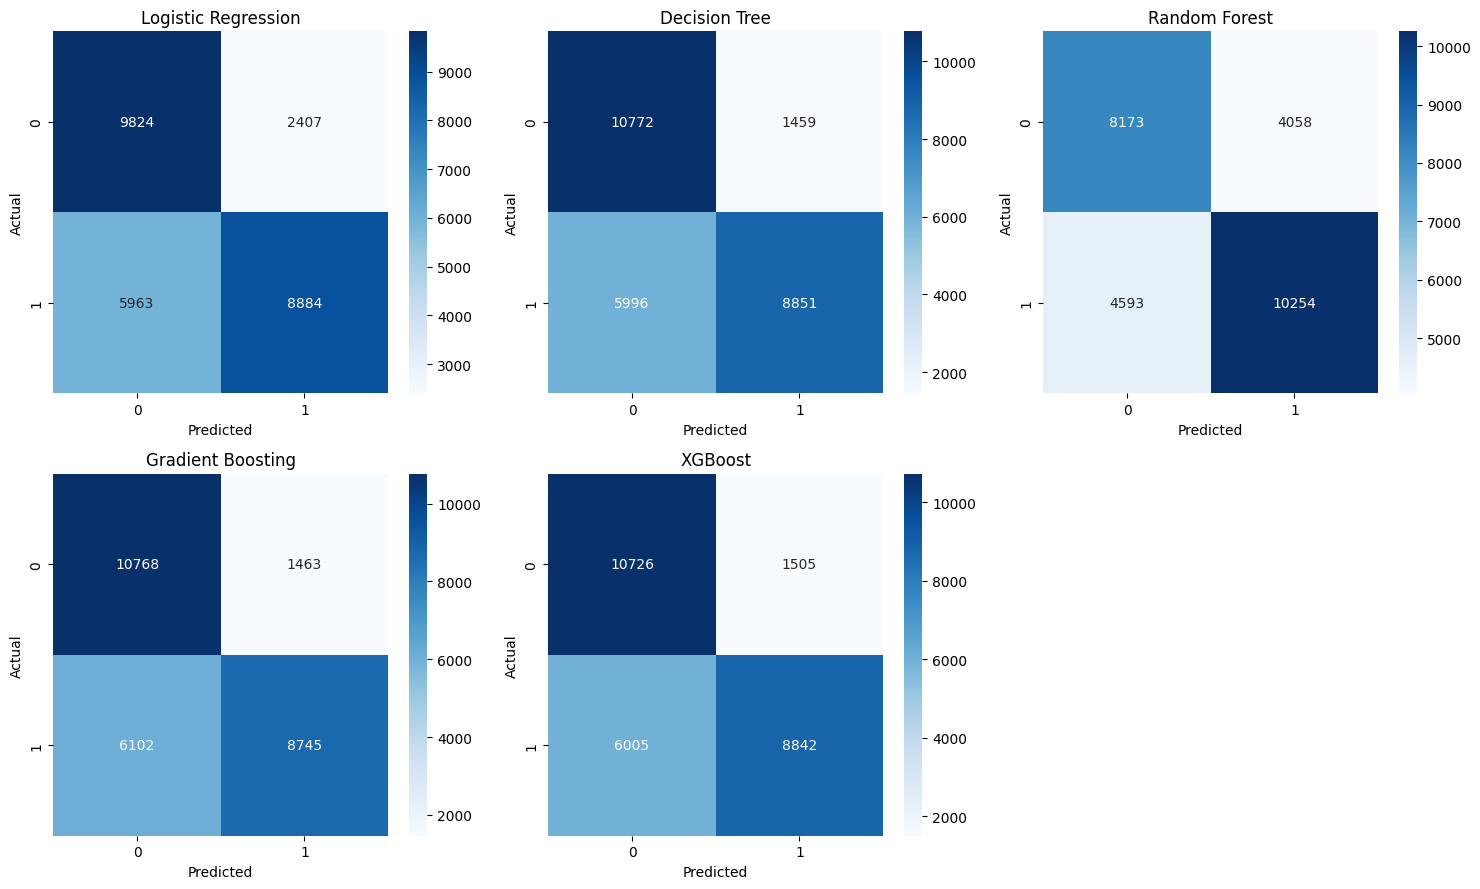

In [24]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_val,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')


axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [25]:
confusion_results = []

for model_name, y_pred in predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred
    ).ravel()

    confusion_results.append({
        'Model': model_name,
        'True Negative': tn,
        'False Positive': fp,
        'False Negative': fn,
        'True Positive': tp
    })

confusion_df = pd.DataFrame(
    confusion_results
)

confusion_df

,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,9824,2407,5963,8884
1,Decision Tree,10772,1459,5996,8851
2,Random Forest,8173,4058,4593,10254
3,Gradient Boosting,10768,1463,6102,8745
4,XGBoost,10726,1505,6005,8842


In [26]:
y_val_pred = xgb_model.predict(
    X_val_processed
)


y_val_proba = xgb_model.predict_proba(
    X_val_processed
)[:, 1]

In [27]:
val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

val_precision = precision_score(
    y_val,
    y_val_pred
)

val_recall = recall_score(
    y_val,
    y_val_pred
)

val_f1 = f1_score(
    y_val,
    y_val_pred
)

val_roc_auc = roc_auc_score(
    y_val,
    y_val_proba
)

val_pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

print("XGBoost Validation Performance")
print("=" * 40)

print("Accuracy :", val_accuracy)
print("Precision:", val_precision)
print("Recall   :", val_recall)
print("F1 Score :", val_f1)
print("ROC-AUC  :", val_roc_auc)
print("PR-AUC   :", val_pr_auc)

XGBoost Validation Performance
Accuracy : 0.7226530762981018
Precision: 0.8545472117521987
Recall   : 0.5955411867717384
F1 Score : 0.7019131539255379
ROC-AUC  : 0.8017275322562616
PR-AUC   : 0.8561742085486947


In [28]:
tn, fp, fn, tp = confusion_matrix(
    y_val,
    y_val_pred
).ravel()

print("XGBoost Validation Confusion Matrix")
print("=" * 40)

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

XGBoost Validation Confusion Matrix
True Negative : 10726
False Positive: 1505
False Negative: 6005
True Positive : 8842


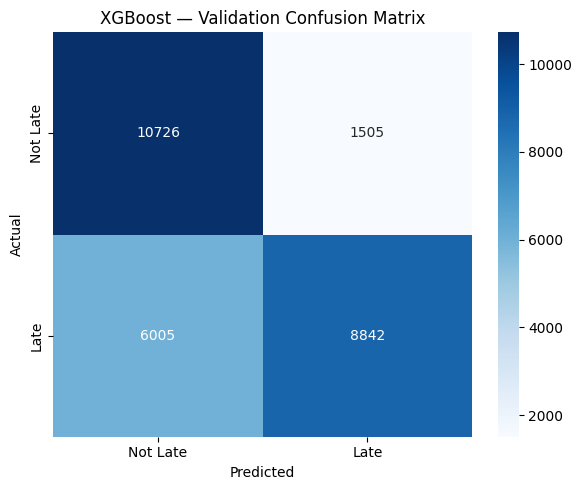

In [29]:
cm = confusion_matrix(
    y_val,
    y_val_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Late', 'Late'],
    yticklabels=['Not Late', 'Late']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost — Validation Confusion Matrix')

plt.tight_layout()
plt.show()

In [30]:
y_val_proba

array([0.33529878, 0.7854159 , 0.40725628, ..., 0.99809784, 0.9975434 ,
       0.8110188 ], shape=(27078,), dtype=float32)

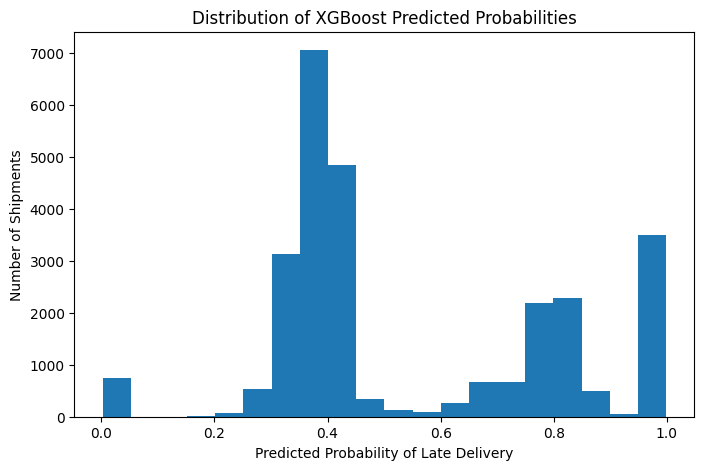

In [31]:


plt.figure(figsize=(8, 5))

plt.hist(
    y_val_proba,
    bins=20
)

plt.xlabel('Predicted Probability of Late Delivery')
plt.ylabel('Number of Shipments')
plt.title('Distribution of XGBoost Predicted Probabilities')

plt.show()

In [32]:
print(y_val_proba.min(), y_val_proba.max())


print(pd.Series(y_val_proba).describe())

0.0020567686 0.9990306
count    27078.000000
mean         0.549237
std          0.256465
min          0.002057
25%          0.381732
50%          0.408182
75%          0.793418
max          0.999031
dtype: float64


In [33]:
thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

threshold_results = []

for threshold in thresholds:

    y_val_threshold = (
        y_val_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_val_threshold
    )

    recall = recall_score(
        y_val,
        y_val_threshold
    )

    f1 = f1_score(
        y_val,
        y_val_threshold
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_threshold
    ).ravel()

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'False Positive': fp,
        'False Negative': fn,
        'True Positive': tp,
        'True Negative': tn
    })

threshold_val_df = pd.DataFrame(
    threshold_results
)

threshold_val_df

,Threshold,Precision,Recall,F1 Score,False Positive,False Negative,True Positive,True Negative
0,0.30,0.573054,0.993803,0.726937,10993,92,14755,1238
1,0.35,0.611805,0.934128,0.739365,8800,978,13869,3431
2,0.40,0.716675,0.761905,0.738598,4472,3535,11312,7759
3,0.45,0.847031,0.610157,0.709341,1636,5788,9059,10595
4,0.50,0.854547,0.595541,0.701913,1505,6005,8842,10726
5,0.55,0.857800,0.590355,0.699382,1453,6082,8765,10778
6,0.60,0.860557,0.586920,0.697874,1412,6133,8714,10819
7,0.65,0.868402,0.577356,0.693584,1299,6275,8572,10932
8,0.70,0.883721,0.547720,0.676286,1070,6715,8132,11161


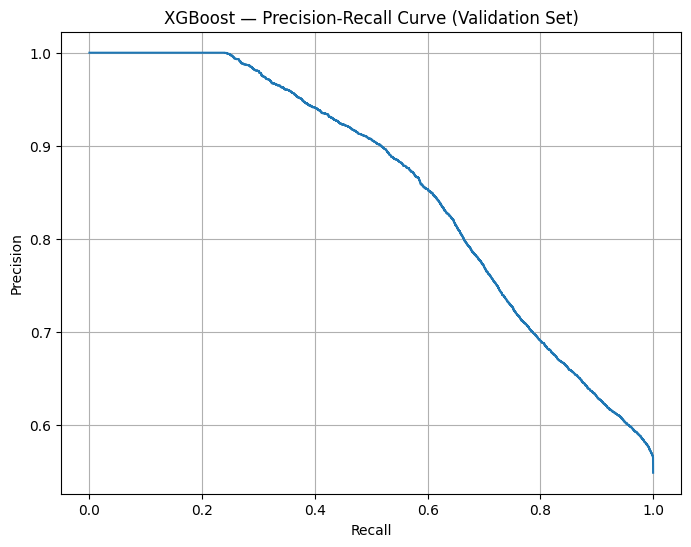

In [34]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('XGBoost — Precision-Recall Curve (Validation Set)')

plt.grid()

plt.show()

In [35]:
from sklearn.metrics import average_precision_score

validation_pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

print("Validation PR-AUC:", validation_pr_auc)

Validation PR-AUC: 0.8561742085486947


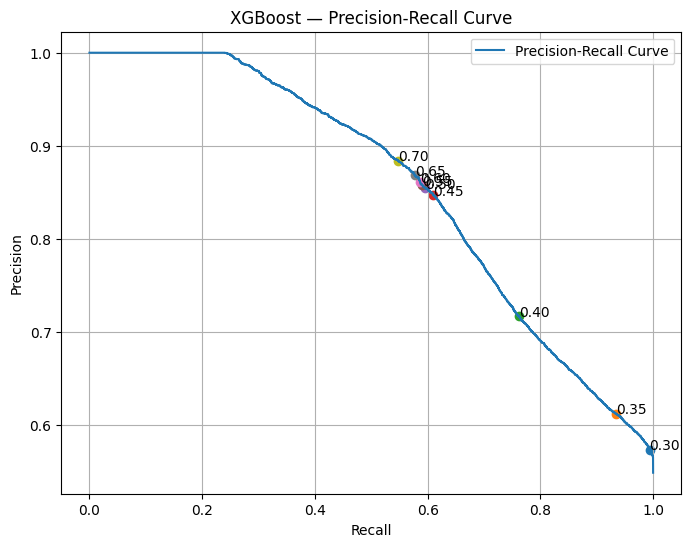

In [36]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label='Precision-Recall Curve'
)

thresholds_to_mark = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

for threshold in thresholds_to_mark:

    idx = (abs(pr_thresholds - threshold)).argmin()

    plt.scatter(
        recall_values[idx],
        precision_values[idx]
    )

    plt.annotate(
        f'{threshold:.2f}',
        (
            recall_values[idx],
            precision_values[idx]
        )
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('XGBoost — Precision-Recall Curve')

plt.legend()
plt.grid()

plt.show()

<b>A threshold of 0.35 was selected because it provided the highest F1 score (73.94%) among the evaluated thresholds while maintaining a high recall of 93.41%, allowing the model to identify most potentially late shipments.</b>

<h3>prediction on test data</h3>

In [37]:
chosen_threshold = 0.35

print("Selected Operating Threshold:", chosen_threshold)

Selected Operating Threshold: 0.35


In [38]:
# Test probabilities
x_test_proba = xgb_model.predict_proba(X_test_processed)[:, 1]

# Apply selected threshold
y_test_final = (x_test_proba >= chosen_threshold).astype(int)

# Metrics
test_accuracy = accuracy_score(y_test, y_test_final)
test_precision = precision_score(y_test, y_test_final)
test_recall = recall_score(y_test, y_test_final)
test_f1 = f1_score(y_test, y_test_final)

print("Final Test Performance at Threshold 0.35")
print("=" * 50)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_test_final)

print("\nConfusion Matrix:")
print(cm)

Final Test Performance at Threshold 0.35
Accuracy : 0.6379
Precision: 0.6114
Recall   : 0.9318
F1 Score : 0.7383

Confusion Matrix:
[[ 3439  8793]
 [ 1012 13834]]


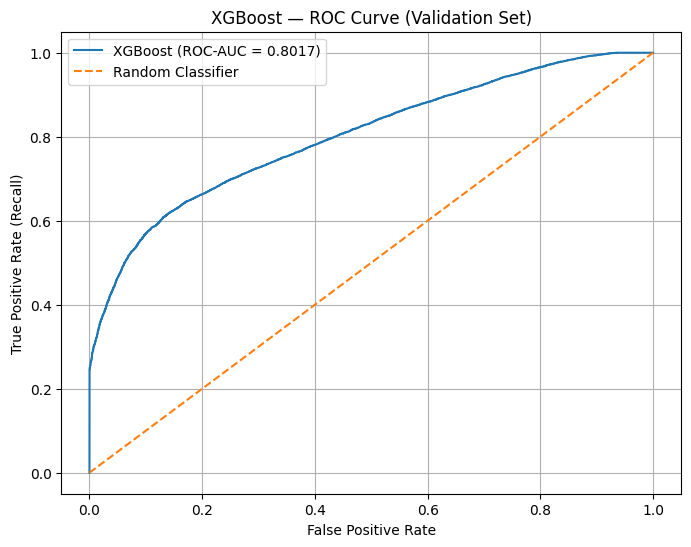

Validation ROC-AUC: 0.8017275322562616


In [39]:
# Calculate ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_val,
    y_val_proba
)

# Calculate ROC-AUC
validation_roc_auc = roc_auc_score(
    y_val,
    y_val_proba
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'XGBoost (ROC-AUC = {validation_roc_auc:.4f})'
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('XGBoost — ROC Curve (Validation Set)')
plt.legend()
plt.grid()
plt.show()

print("Validation ROC-AUC:", validation_roc_auc)

In [40]:
model_summary = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost'
    ],
    'Accuracy': [
        0.690893,
        0.724684,
        0.680516,
        0.720622,
        0.722653
    ],
    'Precision': [
        0.7868,
        0.8585,
        0.7165,
        0.8567,
        0.8545
    ],
    'Recall': [
        0.5984,
        0.5961,
        0.6906,
        0.5890,
        0.5955
    ],
    'F1 Score': [
        0.6798,
        0.7037,
        0.7033,
        0.6981,
        0.7019
    ],
    'ROC-AUC': [
        0.7174,
        0.7839,
        0.7512,
        0.7828,
        0.8017
    ],
    'PR-AUC': [
        0.7294,
        0.8136,
        0.8034,
        0.8432,
        0.8562
    ]
})

model_summary

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.690893,0.7868,0.5984,0.6798,0.7174,0.7294
1,Decision Tree,0.724684,0.8585,0.5961,0.7037,0.7839,0.8136
2,Random Forest,0.680516,0.7165,0.6906,0.7033,0.7512,0.8034
3,Gradient Boosting,0.720622,0.8567,0.5890,0.6981,0.7828,0.8432
4,XGBoost,0.722653,0.8545,0.5955,0.7019,0.8017,0.8562


XGBoost achieved the highest validation ROC-AUC (0.8017) and PR-AUC (0.8562) among the evaluated models, while maintaining strong precision and competitive F1 performance. Therefore, XGBoost was selected for final evaluation and threshold-based risk prediction.

sample prediction


In [41]:
import pandas as pd


sample_data = pd.DataFrame([{
    'Days for shipment (scheduled)': 1,
    'Order Item Discount': 50.0,
    'Order Item Quantity': 2,
    'Sales': 300.0,
    'Product Price': 150.0,
    'Latitude': 18.52,
    'Longitude': 73.85,

    'Type': 'DEBIT',
    'Customer Country': 'United States',
    'Customer Segment': 'Consumer',
    'Market': 'USCA',
    'Customer State': 'CA',
    'Order Region': 'West',
    'Order Country': 'United States',
    'Category Id': 10,
    'Product Card Id': 100,
    'Department Id': 2,

    'Order Year': 2017,
    'Order Month': 6,
    'Order Day': 15,
    'Order Day of Week': 3,
    'Order Hour': 10
}])

selected_features = X_train.columns
sample_data = sample_data[selected_features]

# Apply the already-fitted preprocessor
sample_processed = preprocessor.transform(sample_data)

# Predict probability
late_probability = xgb_model.predict_proba(sample_processed)[0, 1]

# Apply selected threshold
prediction = int(late_probability >= 0.35)

print("Late Delivery Probability:", round(late_probability, 4))
print("Prediction:", prediction)

if prediction == 1:
    print("Risk Level: High Risk")
else:
    print("Risk Level: Low Risk")

Late Delivery Probability: 0.998
Prediction: 1
Risk Level: High Risk


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1, 5, 6, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [42]:
import os
import joblib

# Create a folder to store the trained model
model_folder = r"D:\projects\supply chain project\models"
os.makedirs(model_folder, exist_ok=True)

# Save the existing model, preprocessor, and selected threshold
model_artifacts = {
    'model': xgb_model,
    'preprocessor': preprocessor,
    'threshold': 0.35
}

model_path = os.path.join(
    model_folder,
    'xgboost_supply_chain_model.joblib'
)

joblib.dump(model_artifacts, model_path)

print("Model and preprocessor saved successfully!")
print("Location:", model_path)

Model and preprocessor saved successfully!
Location: D:\projects\supply chain project\models\xgboost_supply_chain_model.joblib
